In [75]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

Датасет представляет собой выгрузку кампаний краудфандинговой платформы Kickstarter (694 062 проекта, 40+ признаков), каждая строка — одна кампания по сбору средств.

Краудфандинг — это рынок, где успех проекта зависит от привлекательности описания, ниши, амбициозности цели, географии и тайминга запуска. Задача отвечает на вопрос «стоит ли запускать кампанию в таком виде или её нужно доработать», а для платформы — «какие проекты с высокой вероятностью провалятся и как им помочь».


Задача — бинарная классификация: по информации, известной на момент запуска кампании (название и краткое описание проекта, категория, страна и регион, целевая сумма сбора, дата запуска и плановая длительность кампании, метаданные автора), предсказать, завершится ли кампания успешно (state == 'successful') или провалится (state == 'failed').

Из данных исключаются кампании со статусами live (кампания идёт в данный момент), canceled (кампания остановлена не по результату сбора средств), suspended (приостановлен), started и submitted (кампания запущена/подана, но не завершена). Признаки-результаты pledged, usd_pledged и backers_count удаляются, поскольку они становятся известны только по завершении кампании.



In [76]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [77]:
df = pd.read_csv(
    "/content/drive/MyDrive/Kickstarter Full Campaigns_694062_25_April_2026.csv",
    low_memory=False,
)

In [78]:
df.shape

(694062, 43)

In [79]:
df.head(10)

,collected_at,backers_count,blurb,category_id,category_name,category_parent_id,category_parent_name,category_url,converted_pledged_amount,country,...,profile_state_changed_at,project_url,spotlight,staff_pick,state,state_changed_at,static_usd_rate,usd_exchange_rate,usd_pledged,usd_type
0,202605,0,A self care dance inclusive workshop for those...,257.0,Workshops,6,Dance,http://www.kickstarter.com/discover/categories...,NaN,US,...,1.604714e+09,https://www.kickstarter.com/projects/brakethru...,False,False,submitted,1605330354,0.000000,NaN,NaN,domestic
1,202605,3,Bringing Forgotten Games Back to Life with Mod...,35.0,Video Games,12,Games,http://www.kickstarter.com/discover/categories...,12.0,US,...,1.710849e+09,https://www.kickstarter.com/projects/111780488...,False,False,failed,1713447139,1.000000,1.000000,12.000000,international
2,202605,41,Guide the animals on their journey to Noah's A...,272.0,Mobile Games,12,Games,http://www.kickstarter.com/discover/categories...,2392.0,US,...,1.425916e+09,https://www.kickstarter.com/projects/152635139...,False,False,failed,1404853457,1.000000,1.000000,2392.000000,international
3,202605,3,Android/PC Mass Multiplayer Online Racing Game...,272.0,Mobile Games,12,Games,http://www.kickstarter.com/discover/categories...,3.0,US,...,1.425916e+09,https://www.kickstarter.com/projects/154271612...,False,False,failed,1424879874,1.000000,1.000000,3.000000,international
4,202605,1,With the funded money I will be hosting the ul...,271.0,Live Games,12,Games,http://www.kickstarter.com/discover/categories...,1.0,US,...,1.461426e+09,https://www.kickstarter.com/projects/172014874...,False,False,failed,1467166444,1.000000,1.000000,1.000000,international
5,202605,1,Conventional shooters in a virtual world have ...,271.0,Live Games,12,Games,http://www.kickstarter.com/discover/categories...,3.0,DE,...,1.432393e+09,https://www.kickstarter.com/projects/562232623...,False,False,failed,1438875720,1.104349,1.090499,3.313046,international
6,202605,0,Remote control a real WIFI web cam paintball/l...,271.0,Live Games,12,Games,http://www.kickstarter.com/discover/categories...,0.0,SE,...,1.427937e+09,https://www.kickstarter.com/projects/gamereali...,False,False,failed,1433123843,0.116235,0.117339,0.000000,international
7,202605,0,"Nerdvanah will be a place for nerds, geeks and...",271.0,Live Games,12,Games,http://www.kickstarter.com/discover/categories...,0.0,US,...,1.431799e+09,https://www.kickstarter.com/projects/976916652...,False,False,failed,1437229558,1.000000,1.000000,0.000000,international
8,202605,4,"Transport system for Warhammer miniatures, wit...",270.0,Gaming Hardware,12,Games,http://www.kickstarter.com/discover/categories...,298.0,FR,...,1.698842e+09,https://www.kickstarter.com/projects/1004-miv/...,False,False,failed,1704189600,1.090256,1.102097,295.459303,international
9,202605,4,StarBoard allows you to play your favourite ta...,270.0,Gaming Hardware,12,Games,http://www.kickstarter.com/discover/categories...,112.0,GB,...,1.507203e+09,https://www.kickstarter.com/projects/112617265...,False,False,failed,1522956600,1.379356,1.408096,110.348481,international


In [80]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 694062 entries, 0 to 694061
Data columns (total 43 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   collected_at              694062 non-null  int64  
 1   backers_count             694062 non-null  int64  
 2   blurb                     693949 non-null  object 
 3   category_id               562406 non-null  float64
 4   category_name             562406 non-null  object 
 5   category_parent_id        694062 non-null  int64  
 6   category_parent_name      694062 non-null  object 
 7   category_url              682828 non-null  object 
 8   converted_pledged_amount  667956 non-null  float64
 9   country                   694062 non-null  object 
 10  created_at                694062 non-null  object 
 11  creator_id                694062 non-null  int64  
 12  creator_name              694058 non-null  object 
 13  creator_url               694062 non-null  o

In [81]:
df = df.drop(columns=["pledged", "usd_pledged", "backers_count", "spotlight"]) #удаляем признаки, т.к они становятся известны только по завершении компании

In [82]:
df.shape

(694062, 39)

Заменим тип категориальных признаков с object на специальный

In [83]:
cat_cols = [
    "category_name",
    "category_parent_name",
    "country",
    "currency",
    "location_country",
    "location_name",
    "location_state",
    "location_type",
    "profile_state",
    "staff_pick",
    "state",
    "usd_type"
]
cat_cols = [c for c in cat_cols if c in df.columns]
df[cat_cols] = df[cat_cols].astype("category")

In [84]:
df['country'].dtype

CategoricalDtype(categories=['AT', 'AU', 'BE', 'CA', 'CH', 'DE', 'DK', 'ES', 'FR', 'GB',
                  'GR', 'HK', 'IE', 'IT', 'JP', 'LU', 'MX', 'NL', 'NO', 'NZ',
                  'PL', 'SE', 'SG', 'SI', 'US'],
, ordered=False, categories_dtype=object)

In [85]:
df.columns

Index(['collected_at', 'blurb', 'category_id', 'category_name',
       'category_parent_id', 'category_parent_name', 'category_url',
       'converted_pledged_amount', 'country', 'created_at', 'creator_id',
       'creator_name', 'creator_url', 'currency', 'deadline', 'fx_rate',
       'goal', 'id', 'launched_at', 'location_country', 'location_id',
       'location_name', 'location_state', 'location_type', 'name',
       'percent_funded', 'profile_blurb', 'profile_id', 'profile_name',
       'profile_project_id', 'profile_state', 'profile_state_changed_at',
       'project_url', 'staff_pick', 'state', 'state_changed_at',
       'static_usd_rate', 'usd_exchange_rate', 'usd_type'],
      dtype='object')

In [86]:
df.index

RangeIndex(start=0, stop=694062, step=1)

In [87]:
df['state']

,state
0,submitted
1,failed
2,failed
3,failed
4,failed
...,...
694057,canceled
694058,failed
694059,failed
694060,failed


In [88]:
type(df['state'])

pandas.core.series.Series

In [89]:
df['state'].dtype

CategoricalDtype(categories=['canceled', 'failed', 'live', 'started', 'submitted',
                  'successful', 'suspended'],
, ordered=False, categories_dtype=object)

In [90]:
df.isnull()

,collected_at,blurb,category_id,category_name,category_parent_id,category_parent_name,category_url,converted_pledged_amount,country,created_at,...,profile_project_id,profile_state,profile_state_changed_at,project_url,staff_pick,state,state_changed_at,static_usd_rate,usd_exchange_rate,usd_type
0,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,True,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
694057,False,False,False,False,False,False,True,True,False,False,...,True,True,True,False,True,False,False,True,False,True
694058,False,False,False,False,False,False,True,True,False,False,...,True,True,True,False,True,False,False,True,False,True
694059,False,False,False,False,False,False,True,True,False,False,...,True,True,True,False,True,False,False,True,False,True
694060,False,False,False,False,False,False,True,True,False,False,...,True,True,True,False,True,False,False,True,False,True


In [91]:
df.isnull().sum()

,0
collected_at,0
blurb,113
category_id,131656
category_name,131656
category_parent_id,0
category_parent_name,0
category_url,11234
converted_pledged_amount,26106
country,0
created_at,0


In [92]:
[feature for feature in df.columns if df[feature].isnull().sum() > 0]

['blurb',
 'category_id',
 'category_name',
 'category_url',
 'converted_pledged_amount',
 'creator_name',
 'deadline',
 'fx_rate',
 'launched_at',
 'location_country',
 'location_id',
 'location_name',
 'location_state',
 'location_type',
 'name',
 'percent_funded',
 'profile_blurb',
 'profile_id',
 'profile_name',
 'profile_project_id',
 'profile_state',
 'profile_state_changed_at',
 'staff_pick',
 'static_usd_rate',
 'usd_exchange_rate',
 'usd_type']

In [93]:
df = df.drop(columns=["percent_funded", "converted_pledged_amount", "state_changed_at", "profile_state_changed_at"]) #утечка, если не удалить - модель может подглядывать в будущее

In [94]:
df.describe()

,collected_at,category_id,category_parent_id,creator_id,fx_rate,goal,id,launched_at,location_id,profile_id,profile_project_id,static_usd_rate,usd_exchange_rate
count,694062.000000,562406.000000,694062.000000,6.940620e+05,679185.000000,6.940620e+05,6.940620e+05,6.863390e+05,6.921210e+05,6.841460e+05,6.841460e+05,684146.000000,671209.000000
mean,202569.381885,138.087928,11.409213,1.073546e+09,0.990676,5.157456e+04,1.074414e+09,1.505204e+09,3.297602e+06,2.774084e+06,2.774084e+06,0.978669,0.993146
std,182.714401,129.120556,5.255463,6.204160e+08,0.499367,2.027958e+06,6.195043e+08,1.724630e+08,6.764003e+06,1.655790e+06,1.655790e+06,0.272462,0.245443
min,201404.000000,20.000000,1.000000,3.000000e+00,0.000000,0.000000e+00,1.293000e+03,0.000000e+00,6.000000e+00,1.100000e+01,1.100000e+01,0.000000,0.000000
25%,202605.000000,34.000000,9.000000,5.359756e+08,1.000000,1.500000e+03,5.373789e+08,1.408034e+09,1.100661e+06,1.300084e+06,1.300084e+06,1.000000,1.000000
50%,202605.000000,46.000000,12.000000,1.072424e+09,1.000000,5.000000e+03,1.074800e+09,1.491292e+09,2.414584e+06,2.990104e+06,2.990104e+06,1.000000,1.000000
75%,202605.000000,273.000000,15.000000,1.609894e+09,1.000000,1.500000e+04,1.610285e+09,1.618457e+09,2.471390e+06,4.221522e+06,4.221522e+06,1.000000,1.000000
max,202605.000000,396.000000,26.000000,2.147483e+09,160.663194,1.000000e+09,2.147476e+09,1.777012e+09,1.000000e+08,5.362178e+06,5.362178e+06,1.716408,1.716408


В датасете имеется много пропусков, сильные выбросы в финансовых показателях (goal варьируется от 0 до 1 миллиарда, в то время как медиана всего в районе 5000, первый квартиль около 1500, третий квартиль около 15 000)

Курсы валют (fx_rate, static_usd_rate) имеют медиану 1.0 (большинство кампаний в долларах), однако имеются экстремальные значения вплоть до 160.663194 (у fx_rate)

Распределения числовых признаков характеризуются высокой дисперсией, наличием нулей и экстремальных выбросов.

In [95]:
df.corr(numeric_only=True)

,collected_at,category_id,category_parent_id,creator_id,fx_rate,goal,id,launched_at,location_id,profile_id,profile_project_id,static_usd_rate,usd_exchange_rate
collected_at,1.000000,0.019397,-0.042492,0.002493,0.031151,-0.001714,-0.002631,0.120546,0.001302,0.076896,0.076896,-0.015070,0.033392
category_id,0.019397,1.000000,0.133894,-0.000090,-0.006614,0.007030,-0.000388,0.085430,0.007861,0.153331,0.153331,-0.001388,-0.011501
category_parent_id,-0.042492,0.133894,1.000000,0.001268,-0.002716,0.001254,-0.000464,-0.055228,-0.010917,-0.063208,-0.063208,0.004323,-0.000408
creator_id,0.002493,-0.000090,0.001268,1.000000,-0.000379,-0.001311,-0.001343,-0.000742,-0.001228,0.000724,0.000724,-0.001533,-0.001414
fx_rate,0.031151,-0.006614,-0.002716,-0.000379,1.000000,-0.014619,0.000660,-0.016924,-0.044901,-0.028276,-0.028276,0.406206,0.636828
goal,-0.001714,0.007030,0.001254,-0.001311,-0.014619,1.000000,0.001600,0.004623,0.004730,0.004759,0.004759,-0.025363,-0.029966
id,-0.002631,-0.000388,-0.000464,-0.001343,0.000660,0.001600,1.000000,0.000082,-0.001496,0.000345,0.000345,-0.000668,-0.000735
launched_at,0.120546,0.085430,-0.055228,-0.000742,-0.016924,0.004623,0.000082,1.000000,0.005154,0.677723,0.677723,0.093751,-0.117914
location_id,0.001302,0.007861,-0.010917,-0.001228,-0.044901,0.004730,-0.001496,0.005154,1.000000,0.007579,0.007579,-0.079563,-0.090283
profile_id,0.076896,0.153331,-0.063208,0.000724,-0.028276,0.004759,0.000345,0.677723,0.007579,1.000000,1.000000,-0.194021,-0.122532


Отсутствие сильной линейной связи между большинством исходных признаков (значения близки к 0), что говорит о низком риске мультиколлинеарности.
Однако корреляция между profile_id и profile_project_id равна 1, а курсы валют static_usd_rate и usd_exchange_rate — 0.98, можно оставить лишь один из признаков. Интересно также то, что корреляция goal с остальными признаками практически нулевая, из чего можно сделать вывод, что значение целевой суммы никак не связано с категорией проекта или географией  

In [96]:
cols_to_drop = ["profile_project_id", "usd_exchange_rate"]

df = df.drop(columns=cols_to_drop)

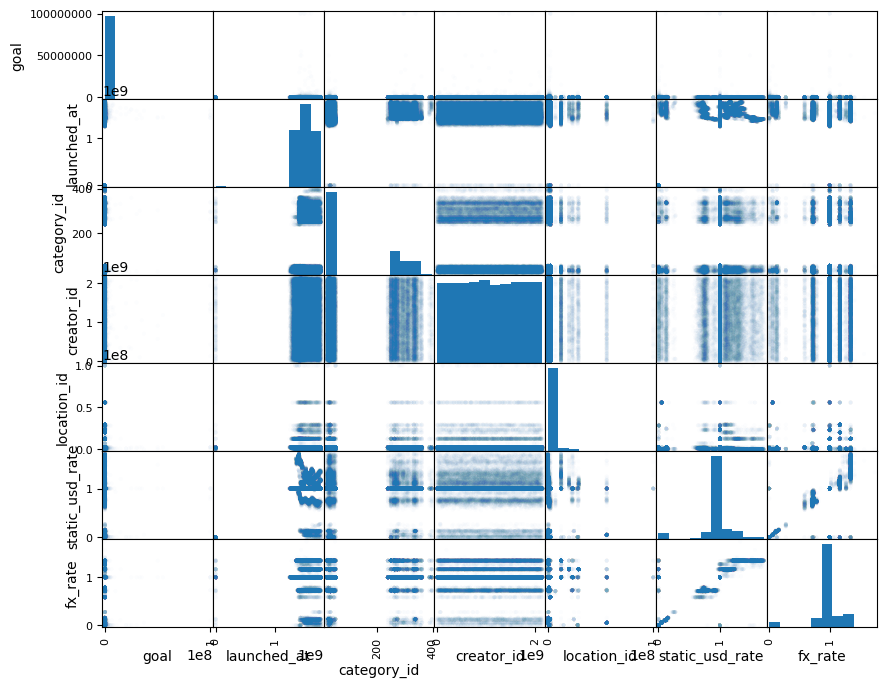

In [97]:
cols_of_interest = ["goal", "launched_at", "category_id", "creator_id", "location_id", "static_usd_rate", "fx_rate"]
pd.plotting.scatter_matrix(df[cols_of_interest].sample(50000), alpha = .01, figsize=(10, 8))
pass

In [98]:
df[df['goal'] > 5000]

,collected_at,blurb,category_id,category_name,category_parent_id,category_parent_name,category_url,country,created_at,creator_id,...,name,profile_blurb,profile_id,profile_name,profile_state,project_url,staff_pick,state,static_usd_rate,usd_type
1,202605,Bringing Forgotten Games Back to Life with Mod...,35.0,Video Games,12,Games,http://www.kickstarter.com/discover/categories...,US,1710848998,1117804888,...,Tethered Gaming: Reviving Lost Legends,NaN,4810413.0,Tethered Gaming: Reviving Lost Legends,inactive,https://www.kickstarter.com/projects/111780488...,False,failed,1.000000,international
2,202605,Guide the animals on their journey to Noah's A...,272.0,Mobile Games,12,Games,http://www.kickstarter.com/discover/categories...,US,1395130404,1526351393,...,Load the Ark,NaN,935020.0,Load the Ark,inactive,https://www.kickstarter.com/projects/152635139...,False,failed,1.000000,international
3,202605,Android/PC Mass Multiplayer Online Racing Game...,272.0,Mobile Games,12,Games,http://www.kickstarter.com/discover/categories...,US,1418608503,154271612,...,Gear Head Racing,NaN,1576797.0,Gear Head Racing,inactive,https://www.kickstarter.com/projects/154271612...,False,failed,1.000000,international
5,202605,Conventional shooters in a virtual world have ...,271.0,Live Games,12,Games,http://www.kickstarter.com/discover/categories...,DE,1432392604,562232623,...,Real Life Shooter by humanoid robots fighting ...,NaN,1916995.0,Real Life Shooter by humanoid robots fighting ...,inactive,https://www.kickstarter.com/projects/562232623...,False,failed,1.104349,international
6,202605,Remote control a real WIFI web cam paintball/l...,271.0,Live Games,12,Games,http://www.kickstarter.com/discover/categories...,SE,1427936656,1381720148,...,GameReality,NaN,1815278.0,GameReality,inactive,https://www.kickstarter.com/projects/gamereali...,False,failed,0.116235,international
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
694055,201404,Years of life and learning culminate into a te...,NaN,NaN,14,Music,NaN,US,1328643230,722047199,...,"Help me record my first full length album: """"""...",NaN,NaN,NaN,NaN,https://www.kickstarter.com/projects/722047199...,NaN,canceled,NaN,NaN
694056,201404,Ballads and blues about our insatiable appetit...,37.0,country & folk,14,Music,NaN,US,1353180823,266697755,...,"G.B. Parker """"""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""...",NaN,NaN,NaN,NaN,https://www.kickstarter.com/projects/gbparker/...,NaN,successful,NaN,NaN
694057,201404,Decipher This is a mentally stimulating and mi...,34.0,tabletop games,12,Games,NaN,US,1302970292,216351752,...,"Decipher This: A game of solving puzzles, code...",NaN,NaN,NaN,NaN,https://www.kickstarter.com/projects/216351752...,NaN,canceled,NaN,NaN
694059,201404,"How I survived sexual abuse, life as an escort...",48.0,nonfiction,18,Publishing,NaN,US,1330536775,79497898,...,"""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""""...",NaN,NaN,NaN,NaN,https://www.kickstarter.com/projects/79497898/...,NaN,failed,NaN,NaN


In [99]:
df[df['goal'] < 100]

,collected_at,blurb,category_id,category_name,category_parent_id,category_parent_name,category_url,country,created_at,creator_id,...,name,profile_blurb,profile_id,profile_name,profile_state,project_url,staff_pick,state,static_usd_rate,usd_type
0,202605,A self care dance inclusive workshop for those...,257.0,Workshops,6,Dance,http://www.kickstarter.com/discover/categories...,US,2020-11-07 01:56:31 UTC,2093160676,...,Brakethru,NaN,4103800.0,Brakethru,inactive,https://www.kickstarter.com/projects/brakethru...,False,submitted,0.000000,domestic
21,202605,It's obvious you won't survive by your wits al...,272.0,Mobile Games,12,Games,http://www.kickstarter.com/discover/categories...,US,1422642399,1997110766,...,"Chip Dip II: Son of Chip Dip! - A Terrible, Te...",NaN,1671029.0,"Chip Dip II: Son of Chip Dip! - A Terrible, Te...",inactive,https://www.kickstarter.com/projects/199711076...,False,failed,1.000000,international
115,202605,"Your kids will look forward to, or freak out, ...",271.0,Live Games,12,Games,http://www.kickstarter.com/discover/categories...,US,1444449714,1552510607,...,Buy A Ghost or Zombie Visit!!!,NaN,2167196.0,Buy A Ghost or Zombie Visit!!!,inactive,https://www.kickstarter.com/projects/ownthemus...,False,failed,1.000000,domestic
134,202605,"Portals, dnd, tabletop games",34.0,Tabletop Games,12,Games,http://www.kickstarter.com/discover/categories...,IT,1718468209,1472491955,...,Portals-Stl Files,NaN,4908680.0,Portals-Stl Files,inactive,https://www.kickstarter.com/projects/solarisga...,False,successful,1.073864,international
142,202605,Great gag gift!,273.0,Playing Cards,12,Games,http://www.kickstarter.com/discover/categories...,US,1570719780,1028342318,...,Toe Jams,Great gag gift!,3830100.0,Toe Jams,active,https://www.kickstarter.com/projects/dumbestki...,False,successful,1.000000,international
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
693852,201412,Why pay $7.99 for a domestic lager? I will mak...,NaN,NaN,10,Food,NaN,US,1404837781,1769348842,...,A $7.99 6-Pack You Deserve!! (Canceled),NaN,NaN,NaN,NaN,https://www.kickstarter.com/projects/176934884...,NaN,canceled,NaN,NaN
693996,201408,Who doesn't love those half popped popcorn ker...,313.0,small batch,10,Food,NaN,US,1407506665,1640602400,...,Half Popped Popcorn,NaN,NaN,NaN,NaN,https://www.kickstarter.com/projects/164060240...,NaN,live,NaN,NaN
694028,201408,TBD,48.0,nonfiction,18,Publishing,NaN,US,1407267287,3621517,...,Future Project,NaN,NaN,NaN,NaN,https://www.kickstarter.com/projects/3621517/m...,NaN,live,NaN,NaN
694029,201408,"i want to make egg salad, because its awesome ...",NaN,NaN,10,Food,NaN,CA,1405379320,796937391,...,Egg Salad,NaN,NaN,NaN,NaN,https://www.kickstarter.com/projects/nervegear...,NaN,live,NaN,NaN


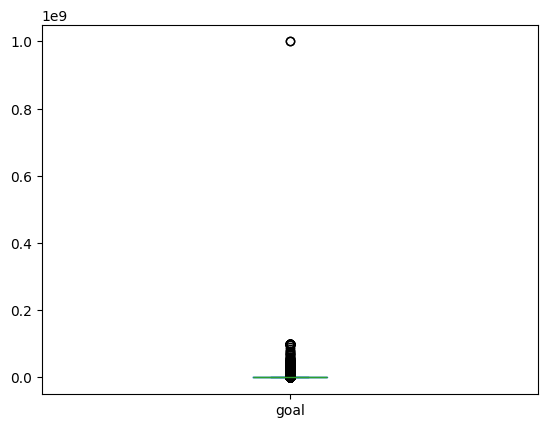

In [100]:
df['goal'].plot(kind='box')
pass

In [101]:
df['goal'].quantile([0.005,.01, 0.025, .05,.1,.25,.5,.75,.9,.95,.99,.995, .999])

,goal
0.005,0.0
0.010,0.0
0.025,70.0
0.050,200.0
0.100,500.0
0.250,1500.0
0.500,5000.0
0.750,15000.0
0.900,49000.0
0.950,89000.0


<Axes: >

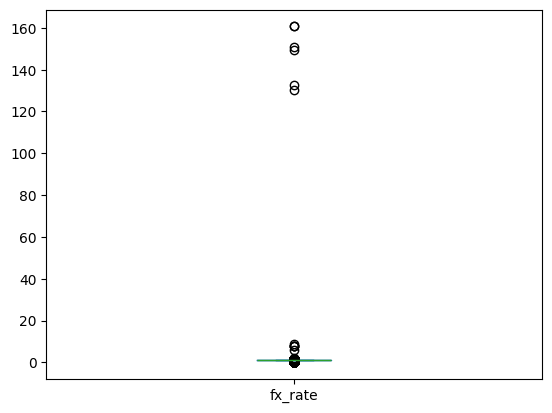

In [102]:
df['fx_rate'].plot(kind='box')

In [103]:
df['fx_rate'].quantile([0.005,.01,.05,.1,.25,.5,.75,.9,.95,.99,.995])

,fx_rate
0.005,0.006268
0.010,0.057312
0.050,0.711925
0.100,0.729385
0.250,1.000000
0.500,1.000000
0.750,1.000000
0.900,1.346009
0.950,1.346009
0.990,1.348561


Эвристика Тьюки как метод борьбы с выбросами для данной задачи не совсем подходит (действительно бывают кампании с высокими целевыми суммами, и это нормально, используя эвристику Тьюки - мы отсечёи их), будем использовать другие методы

In [104]:
df.shape

(694062, 33)

In [105]:
rows_to_drop = df[
    (df['goal'] < df['goal'].quantile(0.025)) | (df['goal'] > df['goal'].quantile(0.999)) |
    (df['fx_rate'] < df['fx_rate'].quantile(0.005)) | (df['fx_rate'] > df['fx_rate'].quantile(0.995))
    ].index
df = df.drop(rows_to_drop)
df.shape

(672859, 33)

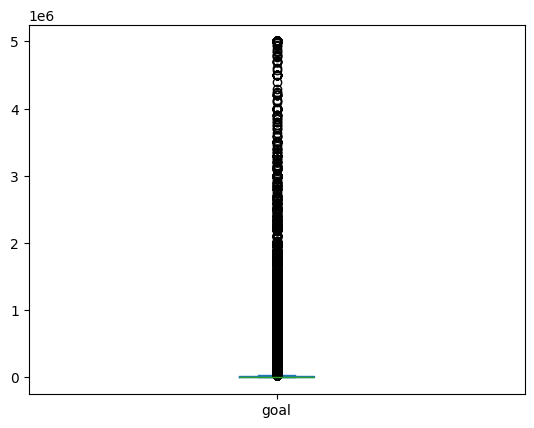

In [106]:
df['goal'].plot(kind='box')
pass

In [107]:
df['goal'].quantile([0.005,.01, 0.025, .05,.1,.25,.5,.75,.9,.95,.99,.995, .999])

,goal
0.005,100.00
0.010,100.00
0.025,200.00
0.050,300.00
0.100,500.00
0.250,1800.00
0.500,5000.00
0.750,15000.00
0.900,48000.00
0.950,83000.00


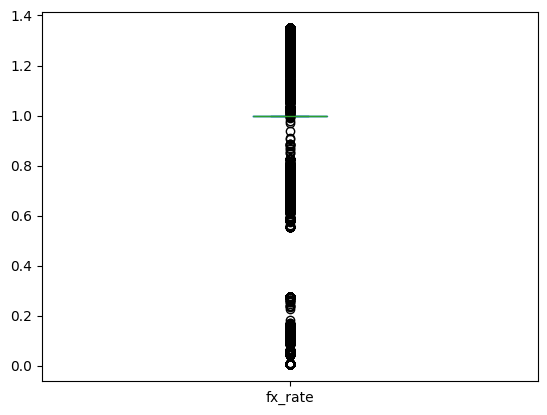

In [108]:
df['fx_rate'].plot(kind='box')
pass

In [109]:
df.describe()

,collected_at,category_id,category_parent_id,creator_id,fx_rate,goal,id,launched_at,location_id,profile_id,static_usd_rate
count,672859.000000,544383.000000,672859.000000,6.728590e+05,658440.000000,6.728590e+05,6.728590e+05,6.716530e+05,6.709880e+05,6.633320e+05,663332.000000
mean,202571.810495,138.577935,11.404786,1.072858e+09,0.993673,2.689240e+04,1.074571e+09,1.511426e+09,3.279499e+06,2.735224e+06,0.994674
std,176.198834,129.214991,5.258238,6.204364e+08,0.231492,1.432425e+05,6.195395e+08,1.390395e+08,6.730016e+06,1.646983e+06,0.242567
min,201404.000000,20.000000,1.000000,3.000000e+00,0.006268,7.000000e+01,1.293000e+03,0.000000e+00,6.000000e+00,1.100000e+01,0.000000
25%,202605.000000,34.000000,9.000000,5.353329e+08,1.000000,1.800000e+03,5.374790e+08,1.408572e+09,1.100908e+06,1.255212e+06,1.000000
50%,202605.000000,46.000000,12.000000,1.071636e+09,1.000000,5.000000e+03,1.075170e+09,1.491770e+09,2.417129e+06,2.939268e+06,1.000000
75%,202605.000000,273.000000,15.000000,1.609507e+09,1.000000,1.500000e+04,1.610600e+09,1.617800e+09,2.471435e+06,4.176627e+06,1.000000
max,202605.000000,396.000000,26.000000,2.147483e+09,1.348561,5.000000e+06,2.147476e+09,1.777012e+09,1.000000e+08,5.362178e+06,1.716408


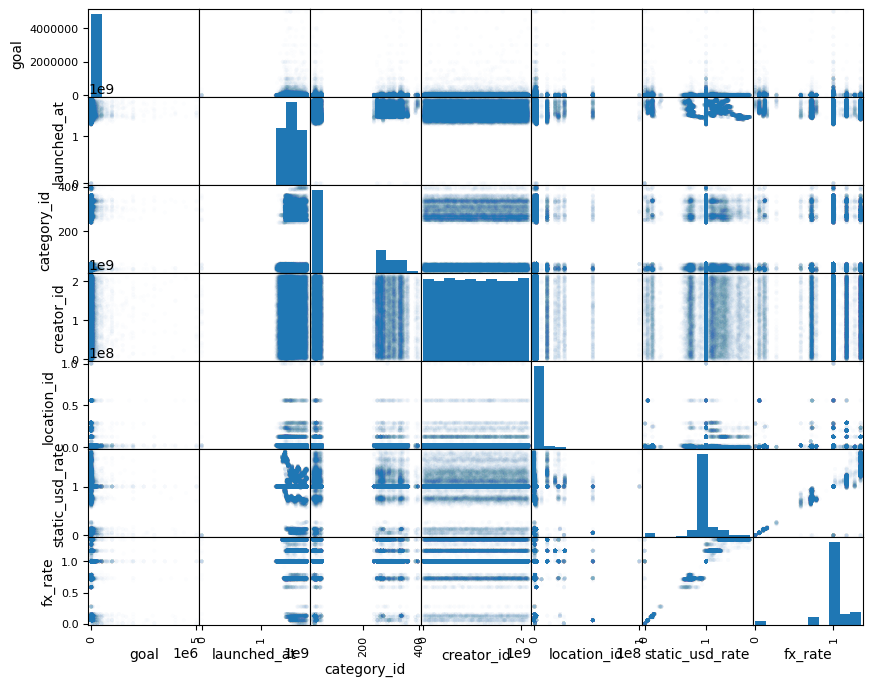

In [110]:
cols_of_interest = ["goal", "launched_at", "category_id", "creator_id", "location_id", "static_usd_rate", "fx_rate"]
pd.plotting.scatter_matrix(df[cols_of_interest].sample(50000), alpha = .01, figsize=(10, 8))
pass

<Axes: xlabel='state', ylabel='count'>

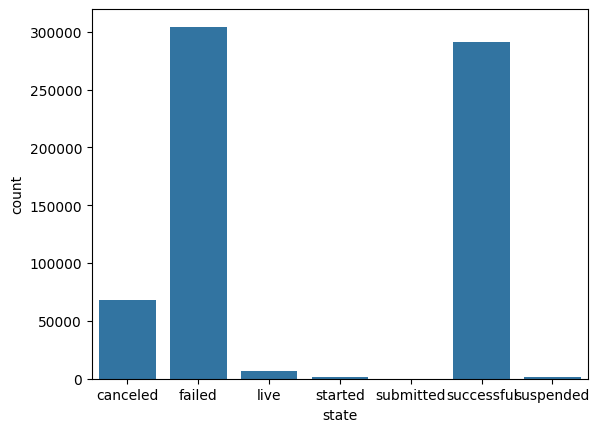

In [111]:
sns.countplot(x='state', data=df)

<Axes: xlabel='country', ylabel='count'>

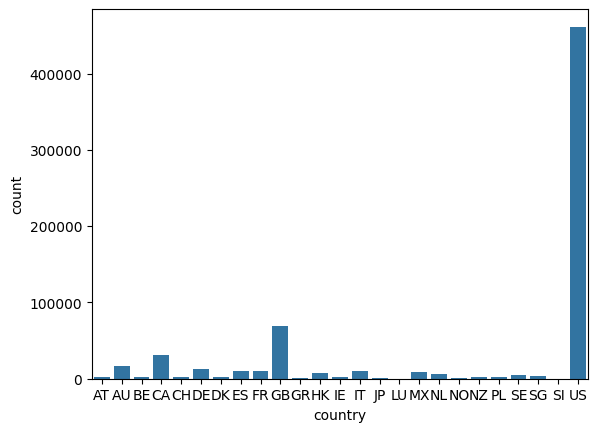

In [112]:
sns.countplot(x='country', data=df)

In [113]:
df['location_name'].value_counts()

,count
location_name,
Los Angeles,29696
London,23836
New York,23502
Chicago,11606
San Francisco,9521
...,...
46012,0
West Saint Cloud,0
35758,0


In [114]:
df['location_name'] = df['location_name'].cat.remove_unused_categories()
df = df[df['state'].isin(['successful', 'failed'])]

In [115]:
df.shape

(595134, 33)

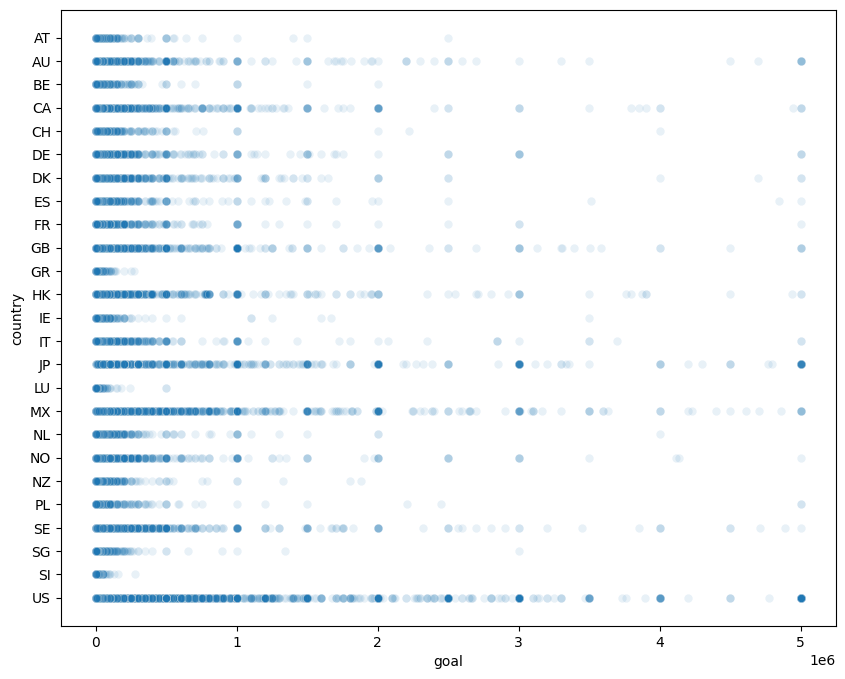

In [116]:
plt.figure(figsize = (10, 8))
sns.scatterplot(x='goal', y='country', data=df, alpha=0.1)
pass

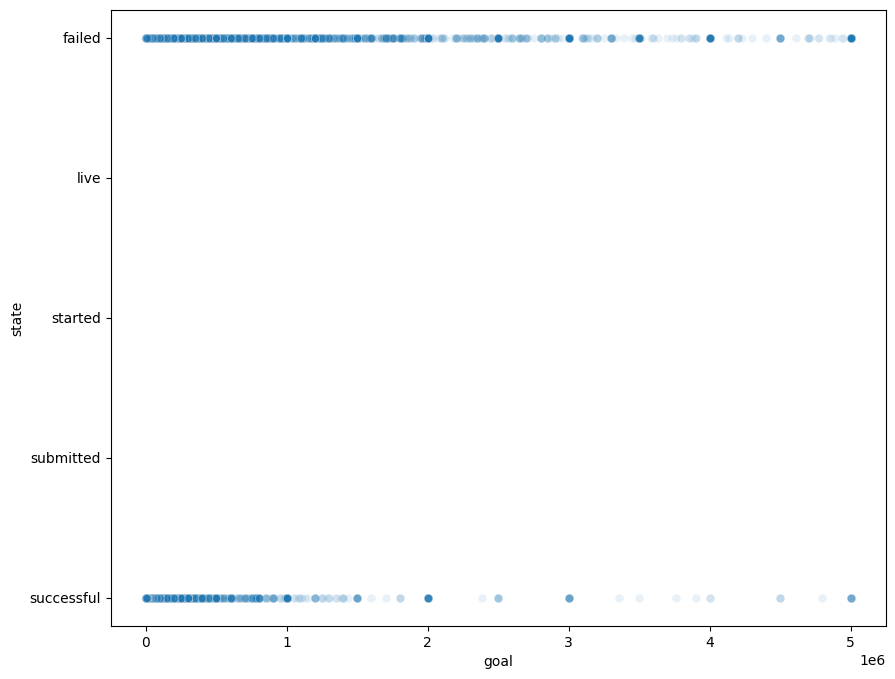

In [117]:
plt.figure(figsize = (10, 8))
sns.scatterplot(x='goal', y='state', data=df, alpha=0.1)
pass

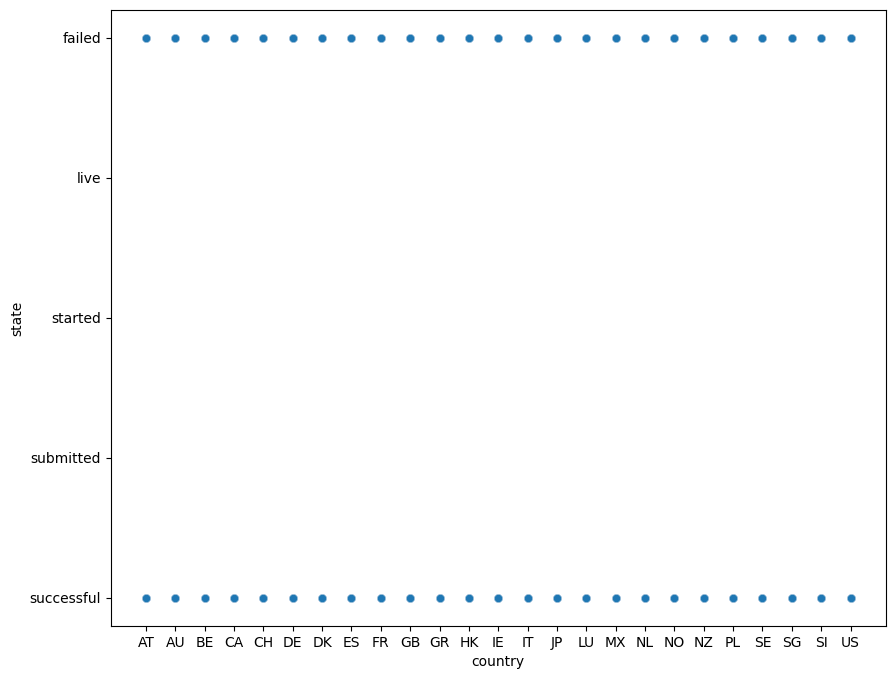

In [118]:
plt.figure(figsize = (10, 8))
sns.scatterplot(x='country', y='state', data=df, alpha=0.1)
pass

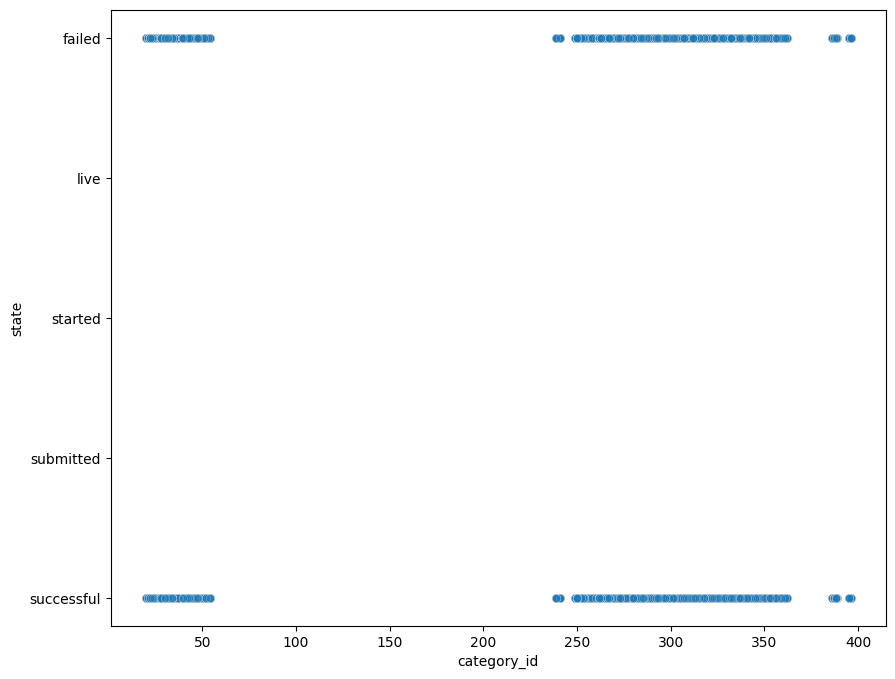

In [119]:
plt.figure(figsize = (10, 8))
sns.scatterplot(x='category_id', y='state', data=df, alpha=0.1)
pass

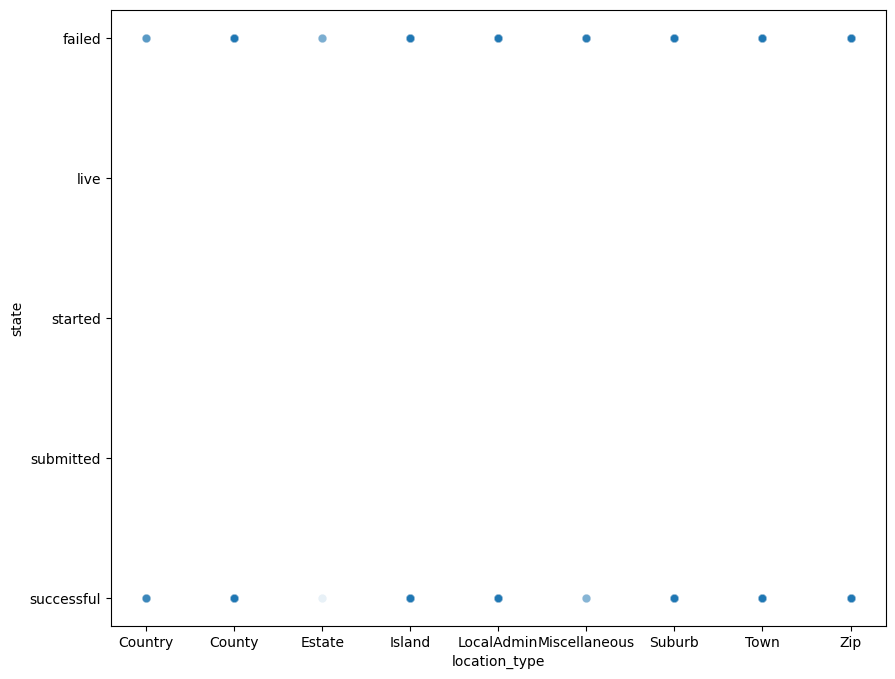

In [120]:
plt.figure(figsize = (10, 8))
sns.scatterplot(x='location_type', y='state', data=df, alpha=0.1)
pass

<Axes: >

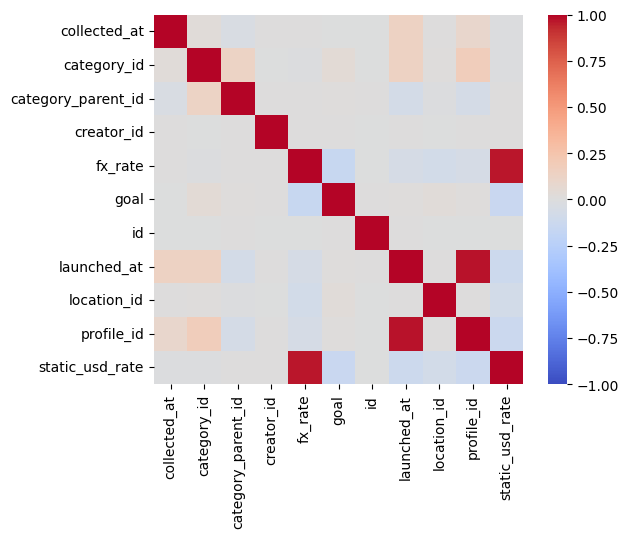

In [121]:
corr_mat = df.corr(numeric_only=True)
sns.heatmap(corr_mat, vmin=-1, vmax=1, square=True, cmap='coolwarm')

In [122]:
cols_to_drop = [
    'blurb', 'category_url', 'creator_name', 'creator_url',
    'name', 'profile_blurb', 'profile_name', 'project_url',
    'id', 'category_id', 'category_parent_id', 'location_id', 'profile_id', 'profile_project_id', 'creator_id',
    'collected_at'
]
cols_to_drop = [c for c in cols_to_drop if c in df.columns]
df = df.drop(columns=cols_to_drop) #удаляем текстовые признаки и id

df['target'] = (df['state'] == 'successful').astype(int)
y = df['target']
X = df.drop(['state', 'target'], axis=1)


In [123]:
X['created_at'] = pd.to_datetime(X['created_at'].astype(float), unit='s', errors='coerce')
X['deadline'] = pd.to_datetime(X['deadline'].astype(float), unit='s', errors='coerce')
X['launched_at'] = pd.to_datetime(X['launched_at'], unit='s', errors='coerce')
X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 595134 entries, 1 to 694061
Data columns (total 17 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   category_name         478664 non-null  category      
 1   category_parent_name  595134 non-null  category      
 2   country               595134 non-null  category      
 3   created_at            595134 non-null  datetime64[ns]
 4   currency              595134 non-null  category      
 5   deadline              595134 non-null  datetime64[ns]
 6   fx_rate               587052 non-null  float64       
 7   goal                  595134 non-null  float64       
 8   launched_at           595134 non-null  datetime64[ns]
 9   location_country      593599 non-null  category      
 10  location_name         593611 non-null  category      
 11  location_state        593461 non-null  category      
 12  location_type         593568 non-null  category      
 13  prof

In [124]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)

N_train, d = X_train.shape
N_test,  d = X_test.shape

N_train, N_test, d

(446350, 148784, 17)

In [125]:
X_train.isna().sum()

,0
category_name,87299
category_parent_name,0
country,0
created_at,0
currency,0
deadline,0
fx_rate,6115
goal,0
launched_at,0
location_country,1118


In [126]:
X_test.isna().sum()

,0
category_name,29171
category_parent_name,0
country,0
created_at,0
currency,0
deadline,0
fx_rate,1967
goal,0
launched_at,0
location_country,417


In [127]:
from sklearn.impute import SimpleImputer
imp_num = SimpleImputer(missing_values=np.nan, strategy='median')
imp_num.fit(X_train[['fx_rate', 'static_usd_rate']])

SimpleImputer(strategy='median')

In [128]:
X_train[['fx_rate', 'static_usd_rate']] = imp_num.transform(X_train[['fx_rate', 'static_usd_rate']])

In [129]:
X_test[['fx_rate', 'static_usd_rate']] = imp_num.transform(X_test[['fx_rate', 'static_usd_rate']])

In [130]:
cat_cols = ['category_name', 'location_country', 'location_name',
            'location_state', 'location_type', 'profile_state',
            'staff_pick', 'usd_type']


for col in cat_cols:
    most_frequent = X_train[col].mode()[0]

    X_train[col] = X_train[col].fillna(most_frequent)
    X_test[col] = X_test[col].fillna(most_frequent)


In [131]:
X_train.isna().sum()

,0
category_name,0
category_parent_name,0
country,0
created_at,0
currency,0
deadline,0
fx_rate,0
goal,0
launched_at,0
location_country,0


In [132]:
X_test.isna().sum()

,0
category_name,0
category_parent_name,0
country,0
created_at,0
currency,0
deadline,0
fx_rate,0
goal,0
launched_at,0
location_country,0


In [133]:
cat_cols_all = df.select_dtypes(include=['category']).columns

cardinality = pd.DataFrame({
    'n_unique': df[cat_cols_all].nunique(),
    'ratio_unique': (df[cat_cols_all].nunique() / len(df) * 100).round(2),
    'sample_values': [df[col].dropna().unique()[:3].tolist() for col in cat_cols_all]
}).sort_values('n_unique', ascending=False)

print(cardinality)

                      n_unique  ratio_unique  \
location_name            23190          3.90   
location_state            1608          0.27   
location_country           221          0.04   
category_name              186          0.03   
country                     25          0.00   
category_parent_name        16          0.00   
currency                    15          0.00   
location_type                9          0.00   
profile_state                2          0.00   
staff_pick                   2          0.00   
state                        2          0.00   
usd_type                     2          0.00   

                                                sample_values  
location_name                  [Albertville, Seattle, Beacon]  
location_state                                   [AL, WA, NY]  
location_country                                 [US, DE, FR]  
category_name         [Video Games, Mobile Games, Live Games]  
country                                          [US, D

In [134]:
cols_to_drop_ = ['location_name', 'location_state'] #Приходится удалить, т.к много уникальных значений -> переполнение памяти при кодировании категориальных признаков

X_train = X_train.drop(columns=[c for c in cols_to_drop_ if c in X_train.columns])
X_test = X_test.drop(columns=[c for c in cols_to_drop_ if c in X_test.columns])

In [135]:
from sklearn.preprocessing import OneHotEncoder

new_cat_cols = ['category_name', 'category_parent_name', 'location_country',
                'location_type', 'profile_state', 'country',
                'staff_pick', 'usd_type', 'currency']

enc = OneHotEncoder(drop='if_binary', sparse_output=False, handle_unknown='ignore')
enc.fit(X_train[new_cat_cols])

OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False)

In [136]:
dummies = pd.DataFrame(enc.transform(X_train[new_cat_cols]),
                       columns=enc.get_feature_names_out(), index=X_train.index)
dummies.head()

,category_name_3D Printing,category_name_Academic,category_name_Accessories,category_name_Action,category_name_Animals,category_name_Animation,category_name_Anthologies,category_name_Apparel,category_name_Apps,category_name_Architecture,...,currency_GBP,currency_HKD,currency_JPY,currency_MXN,currency_NOK,currency_NZD,currency_PLN,currency_SEK,currency_SGD,currency_USD
592784,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
521926,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
18391,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
637653,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
514086,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [137]:
X_train = pd.concat((X_train, dummies), axis=1).drop(new_cat_cols, axis=1)

In [138]:
dummies_test = pd.DataFrame(
    enc.transform(X_test[new_cat_cols]),
    columns=enc.get_feature_names_out(),
    index=X_test.index
)

X_test = pd.concat((X_test, dummies_test), axis=1).drop(new_cat_cols, axis=1)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [139]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 446350 entries, 592784 to 138690
Columns: 470 entries, created_at to currency_USD
dtypes: datetime64[ns](3), float64(467)
memory usage: 1.6 GB


In [140]:
for col in ['created_at', 'deadline', 'launched_at']: #перевод в секунды
    if col in X_train.columns:
        X_train[col] = X_train[col].astype('int64') // 10**9
        X_test[col] = X_test[col].astype('int64') // 10**9

In [141]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 446350 entries, 592784 to 138690
Columns: 470 entries, created_at to currency_USD
dtypes: float64(467), int64(3)
memory usage: 1.6 GB


In [142]:
from sklearn.preprocessing import RobustScaler

cols_to_scale = ['goal', 'fx_rate', 'static_usd_rate', 'launched_at', 'created_at', 'deadline']
cols_to_scale = [c for c in cols_to_scale if c in X_train.columns]

scaler = RobustScaler() #выбрана эта нормализация, т.к RobustScaler устойчив к выбросам

In [143]:
X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

In [144]:
sampled_indices = X_train.sample(n=100000, random_state=42).index

# Таблица слишком большая, происходит переполнение памяти. Берем меньшее количество объектов
X_train = X_train.loc[sampled_indices]
y_train = y_train.loc[sampled_indices]

In [145]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(n_estimators=50, max_depth=10, max_features='sqrt', random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(max_depth=10, n_estimators=50, random_state=42)

In [148]:
y_train_predict = model.predict(X_train)
y_test_predict = model.predict(X_test)
err_train = np.mean(y_train != y_train_predict)
err_test  = np.mean(y_test  != y_test_predict)

print(err_train, err_test)

0.22751 0.23351301215184428


In [150]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_test_predict)
print(cm)

[[65593 10496]
 [24247 48448]]


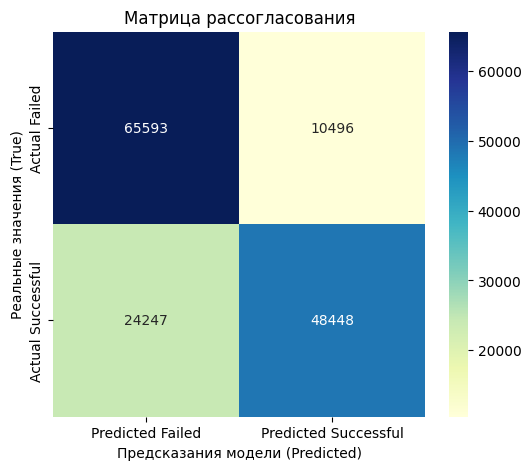

In [152]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    xticklabels=['Predicted Failed', 'Predicted Successful'],
    yticklabels=['Actual Failed', 'Actual Successful']
)
plt.ylabel('Реальные значения (True)')
plt.xlabel('Предсказания модели (Predicted)')
plt.title('Матрица рассогласования')
plt.show()

In [153]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_test_predict, target_names=['Failed', 'Successful']))

              precision    recall  f1-score   support

      Failed       0.73      0.86      0.79     76089
  Successful       0.82      0.67      0.74     72695

    accuracy                           0.77    148784
   macro avg       0.78      0.76      0.76    148784
weighted avg       0.77      0.77      0.76    148784



Разница между ошибками на обучающей и тестовой выборке мала, а значит, модель не переобучилась. Модель хорошо предсказывает провальные проекты (значение recall 0.86 для failed). Если бы мы запускали платформу и хотели заранее узнать, провалится ли проект, модель сработала бы отлично. Однако с успешными проектами ситуация хуже: Recall всего 0.67. Это значит, что из всех успешных проектов модель пропустила почти треть — она ошибочно отнесла их к "провальным". Precision для успешных высокий 0.82, то есть если модель говорит "успех", то она почти не ошибается. Но она часто говорит "провал" там, где на самом деле был успех.

Результаты могли быть лучше, если бы из-за нехватки памяти не пришлось обрезать количество объектов :(

Эта модель была испробована первой, т.к RandomForest достаточно популярен и эффективен. Knn для нашего случая использовать проблематично, т.к для предсказания данная модель требует хранить весь обучающий набор данных в оперативной памяти целиком, а т.к у нас большое количество объектов и признаков - возникает большой расход памяти и она переполняется.

Попробуем улучшить результат: возьмём другие значение гиперпараметров и попробуем другие модели


In [154]:
model = RandomForestClassifier(n_estimators=100, max_depth=15, max_features='sqrt', random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(max_depth=15, random_state=42)

In [155]:
y_train_predict = model.predict(X_train)
y_test_predict = model.predict(X_test)
err_train = np.mean(y_train != y_train_predict)
err_test  = np.mean(y_test  != y_test_predict)

print(err_train, err_test)

0.20532 0.22304817722335735


In [156]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_test_predict)
print(cm)

[[65328 10761]
 [22425 50270]]


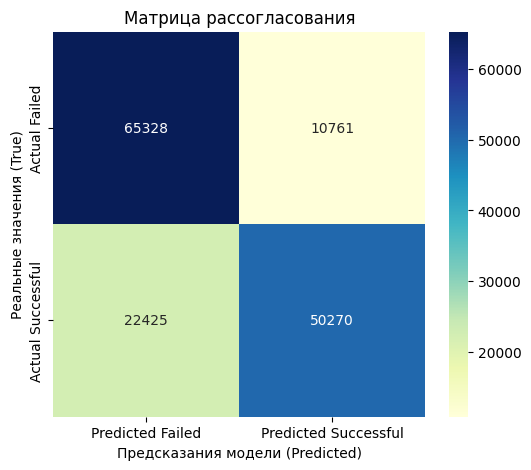

In [157]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    xticklabels=['Predicted Failed', 'Predicted Successful'],
    yticklabels=['Actual Failed', 'Actual Successful']
)
plt.ylabel('Реальные значения (True)')
plt.xlabel('Предсказания модели (Predicted)')
plt.title('Матрица рассогласования')
plt.show()

In [158]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_test_predict, target_names=['Failed', 'Successful']))

              precision    recall  f1-score   support

      Failed       0.74      0.86      0.80     76089
  Successful       0.82      0.69      0.75     72695

    accuracy                           0.78    148784
   macro avg       0.78      0.78      0.77    148784
weighted avg       0.78      0.78      0.78    148784



Разница между ошибками на трейне и тесте увеличилась почти вдвое - это связано с тем, что мы увеличили максимальную глубину деревьев. Увеличивая max_depth дальше, эта разница будет увеличиваться всё больше, и мы можем получить переобучение. Пока данная разница незначительна и находится в допустимых пределах. Почти по всем метрикам модель стала показывать лучше результаты, хоть и незначительно (отличия в сотых долях)

In [166]:
from sklearn.ensemble import GradientBoostingClassifier
model = GradientBoostingClassifier(n_estimators = 100, max_depth=15, max_features='sqrt', random_state=42)
model.fit(X_train, y_train)

GradientBoostingClassifier(max_depth=10, max_features='sqrt', random_state=42)

In [169]:
y_train_predict = model.predict(X_train)
y_test_predict = model.predict(X_test)
err_train = np.mean(y_train != y_train_predict)
err_test  = np.mean(y_test  != y_test_predict)

print(err_train, err_test)

0.19027 0.2089471986235079


In [170]:
cm = confusion_matrix(y_test, y_test_predict)
print(cm)

[[64550 11539]
 [19549 53146]]


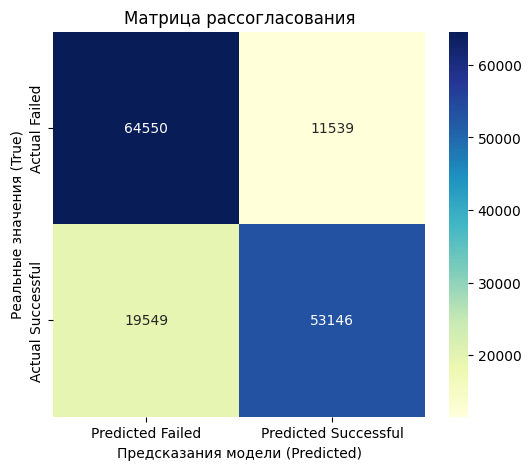

In [171]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    xticklabels=['Predicted Failed', 'Predicted Successful'],
    yticklabels=['Actual Failed', 'Actual Successful']
)
plt.ylabel('Реальные значения (True)')
plt.xlabel('Предсказания модели (Predicted)')
plt.title('Матрица рассогласования')
plt.show()

In [172]:
print(classification_report(y_test, y_test_predict, target_names=['Failed', 'Successful']))

              precision    recall  f1-score   support

      Failed       0.77      0.85      0.81     76089
  Successful       0.82      0.73      0.77     72695

    accuracy                           0.79    148784
   macro avg       0.79      0.79      0.79    148784
weighted avg       0.79      0.79      0.79    148784



Использование градиентного бустинга позволило добиться лучших результатов. Незначительно упал Recall для Failed (т.е модель стала чуть хуже предсказывать провальные объекты), но остальные метрики выросли, модель стала лучше распознавать успешные проекты

In [173]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

base_estimator = DecisionTreeClassifier(max_depth=1)
model = AdaBoostClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

AdaBoostClassifier(n_estimators=100, random_state=42)

In [174]:
y_train_predict = model.predict(X_train)
y_test_predict = model.predict(X_test)
err_train = np.mean(y_train != y_train_predict)
err_test  = np.mean(y_test  != y_test_predict)

print(err_train, err_test)

0.22867 0.22996424346703948


In [175]:
cm = confusion_matrix(y_test, y_test_predict)
print(cm)

[[61995 14094]
 [20121 52574]]


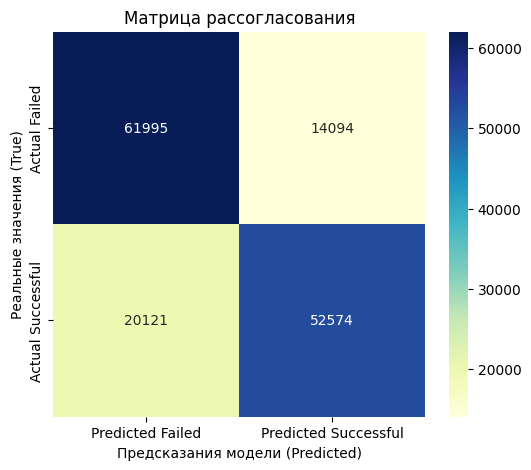

In [176]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    xticklabels=['Predicted Failed', 'Predicted Successful'],
    yticklabels=['Actual Failed', 'Actual Successful']
)
plt.ylabel('Реальные значения (True)')
plt.xlabel('Предсказания модели (Predicted)')
plt.title('Матрица рассогласования')
plt.show()

In [177]:
print(classification_report(y_test, y_test_predict, target_names=['Failed', 'Successful']))

              precision    recall  f1-score   support

      Failed       0.75      0.81      0.78     76089
  Successful       0.79      0.72      0.75     72695

    accuracy                           0.77    148784
   macro avg       0.77      0.77      0.77    148784
weighted avg       0.77      0.77      0.77    148784



AdaBoost показал результаты на уровне RandomForest, хуже чем градиентный бустинг

In [178]:
from sklearn.neural_network import MLPClassifier
model = MLPClassifier(
    hidden_layer_sizes=(64,),
    max_iter=20,
    learning_rate_init=0.001,
    early_stopping=True,
    random_state=42
)
model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


MLPClassifier(early_stopping=True, hidden_layer_sizes=(64,), max_iter=20,
              random_state=42)

In [179]:
y_train_predict = model.predict(X_train)
y_test_predict = model.predict(X_test)
err_train = np.mean(y_train != y_train_predict)
err_test  = np.mean(y_test  != y_test_predict)

print(err_train, err_test)

0.19748 0.2108291214109044


In [180]:
cm = confusion_matrix(y_test, y_test_predict)
print(cm)

[[62871 13218]
 [18150 54545]]


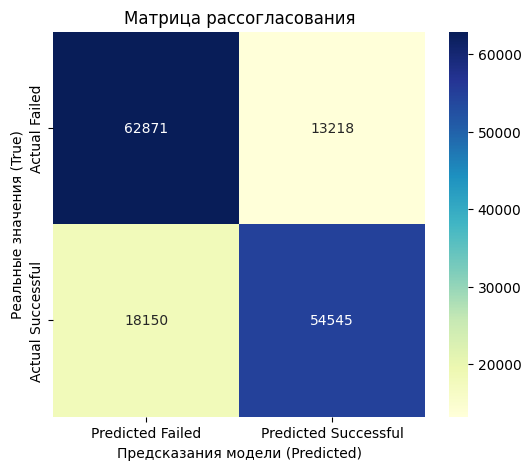

In [181]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    xticklabels=['Predicted Failed', 'Predicted Successful'],
    yticklabels=['Actual Failed', 'Actual Successful']
)
plt.ylabel('Реальные значения (True)')
plt.xlabel('Предсказания модели (Predicted)')
plt.title('Матрица рассогласования')
plt.show()

In [182]:
print(classification_report(y_test, y_test_predict, target_names=['Failed', 'Successful']))

              precision    recall  f1-score   support

      Failed       0.78      0.83      0.80     76089
  Successful       0.80      0.75      0.78     72695

    accuracy                           0.79    148784
   macro avg       0.79      0.79      0.79    148784
weighted avg       0.79      0.79      0.79    148784



MLP показала результаты, сравнимые с градиентным бустингом. MLP показал лучшие результаты recall и f1-score для successful среди всех моделей, но precision для successful ниже, чем у градиентного бустинга, т.е модель является более "оптимистичной". Recall и F1-score для Failed у MLP хуже, чем у градиентного бустинга, т.е она хуже предсказываем класс Failed (делает это более осторожно, что заметно из улучшившийся метрики precision для Failed). Показатели Accuracy у этих двух моделей одинаковы и являются лучшими среди всех моделей

Общий вывод:
В ходе выполнения работы была решена задача бинарной классификации — предсказание успешности краудфандинговых кампаний на платформе Kickstarter.

Исходный датасет содержал более 694 000 проектов и 43 признака. В ходе разведочного анализа данных (EDA) были выявлены и устранены критические проблемы, такие как утечка данных, выбросы, пропуски, высокая кардинальность (признаки с большим количеством уникальных значений были удалены, т.к иначе это приводило к переполнению памяти). Также пришлось сократить число объектов в обучающей выборке, т.к использование полной обучающей выборки приводило к слишком большому расходу памяти.  

Для сравнения было протестировано 4 различных модели: RandomForest, Градиентный бустинг, AdaBoost, MLP. KNN не подошёл из-за требований к памяти. Градиентный бустинг и нейронные сети (MLP) оказались лучшими. Лучше всего модели предсказывают провальные проекты, особенно выделяется в этом RandomForest, показавший лучший результат по Recall для провальных кампаний, что для данной задачи является довольно важным. Однако это достигается ценой просадки общего качества: он хуже находит успешные кампании и проигрывает бустингу и нейронным сетям по accuracy (для GBT и MLP он равен 0.79)

Результаты можно улучшить, если увеличить количество объектов в обучающей выборке, но стоит соблюдать ограничение по памяти